In [357]:
import pandas as pd
import re
import string
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans , DBSCAN , AgglomerativeClustering
import matplotlib.pyplot as plt

In [358]:
nltk.download('stopwords')
nltk.download('wordnet')
df = pd.read_csv("musicLyrics.csv")  
df = df.dropna()
stop_words = set(stopwords.words('english'))
# print(stop_words)
stemmer = PorterStemmer()
# print(stemmer.stem("running"))
lemmatizer = WordNetLemmatizer()
print(lemmatizer)

<WordNetLemmatizer>


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\User\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\User\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [359]:
def wag(text, method="lemmatization"):
    text = text.lower()
    text = re.sub(r'\n', ' ', text)
    text = re.sub(r'\[.*?\]', '', text)
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    text = re.sub(f"[{re.escape(string.punctuation)}]", '', text)
    words = text.split()
    words = [word for word in words if word not in stop_words]
    if method == "stemming":
        words = [stemmer.stem(word) for word in words]
    elif method == "lemmatization":
        words = [lemmatizer.lemmatize(word) for word in words]
    return " ".join(words)

In [360]:
df = pd.read_csv("musicLyrics.csv")
df = df.dropna()
clean = []
for line in df["Lyric"]:
    clean.append(wag(line, method="stemming"))
df = pd.DataFrame({"music": clean})
df.to_csv("new.csv", index=False)

 ## دلیل انجام پیش‌پردازش روی مجموعه داده متن:

هدف پیش‌پردازش متن کاهش نویز، نرمال‌سازی و بهبود کیفیت داده‌هاست تا مدل بتواند بهتر روی داده‌ها کار کند.

روش‌هایی مثل کوچک کردن حروف، حذف علائم نگارشی، حذف کلمات پرتکرار و تبدیل کلمات به شکل ریشه یا پایه استفاده شده.

فرق lemmatization با stemming این است که 

اولی کلمات را به شکل واقعی و معنی‌دار دیکشنری تبدیل می‌کند، اما دومی فقط انتهای کلمات را کوتاه می‌کند و ممکن است کلمات غیرواقعی بسازد.

برای تحلیل متن ترانه‌ها، lemmatization انتخاب بهتری است چون معنای کلمات را بهتر حفظ می‌کند و برای تحلیل‌های معنایی مناسب‌تر است.


استخراج ویژگی‌ها باعث تبدیل متن خام به داده‌های عددی می‌شود که مدل‌های یادگیری ماشین بتوانند بفهمند و پردازش کنند. بدون این کار، مدل نمی‌تواند معنای متن را درک کند و فقط خواندن متن خام کافی نیست. استخراج ویژگی‌ها دقت و کیفیت تحلیل را افزایش می‌دهد.


In [361]:
model = SentenceTransformer('all-MiniLM-L6-v2')
embeddings = model.encode(df["music"].tolist(), show_progress_bar=True)

Batches:   0%|          | 0/94 [00:00<?, ?it/s]

In [362]:
print(embeddings.shape)

(2999, 384)


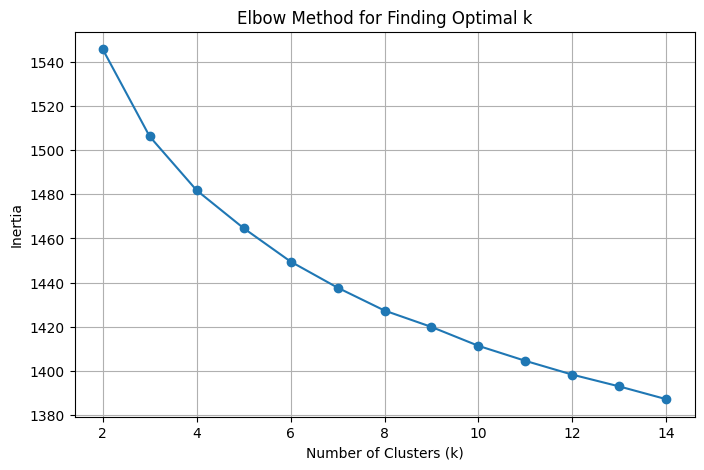

In [363]:
inertia = []
k_range = range(2, 15)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=0)
    kmeans.fit(embeddings)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_range, inertia, marker='o')
plt.title('Elbow Method for Finding Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.grid(True)
plt.show()


In [364]:
k_optimal = 2
kmeans = KMeans(n_clusters=k_optimal, random_state=42)
labels = kmeans.fit_predict(embeddings)
df["cluster"] = labels
df.to_csv("clustered.csv", index=False)


In [365]:
from sklearn.metrics import silhouette_score, homogeneity_score
sil_score = silhouette_score(embeddings, df['cluster'])
print(f"Silhouette Score: {sil_score:.4f}")

Silhouette Score: 0.0560


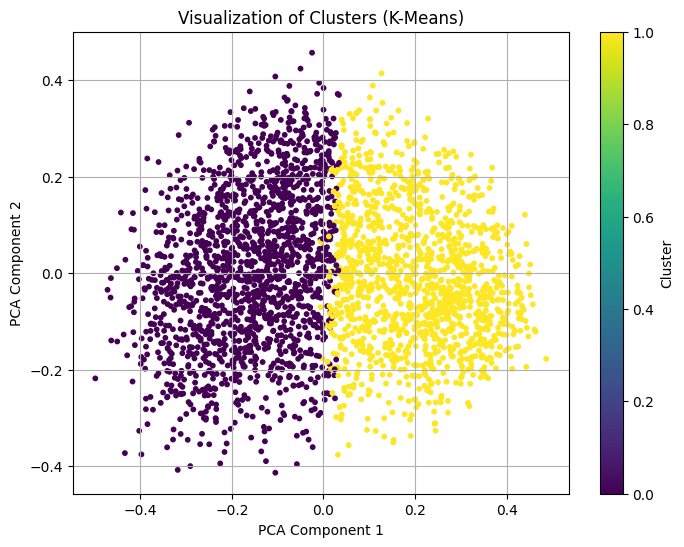

In [366]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
reduced = pca.fit_transform(embeddings)

plt.figure(figsize=(8, 6))
plt.scatter(reduced[:, 0], reduced[:, 1], c=df["cluster"], cmap='viridis', s=10)
plt.title("Visualization of Clusters (K-Means)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.grid(True)
plt.colorbar(label="Cluster")
plt.show()


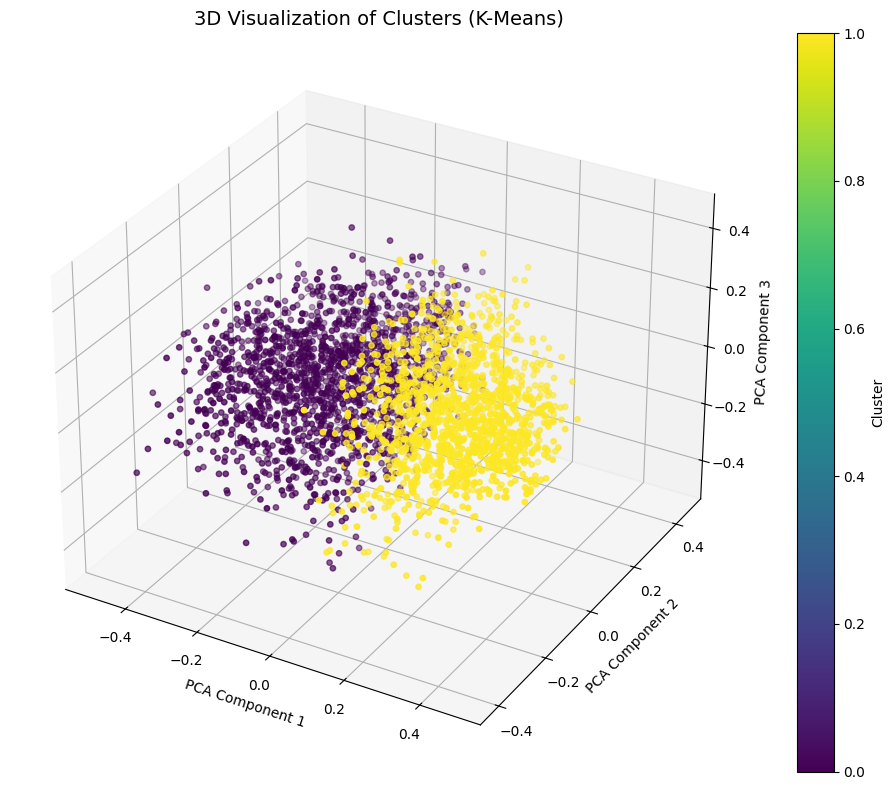

In [367]:
from sklearn.decomposition import PCA
from mpl_toolkits.mplot3d import Axes3D
pca = PCA(n_components=3)
reduced_3d = pca.fit_transform(embeddings)
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
sc = ax.scatter(reduced_3d[:, 0], reduced_3d[:, 1], reduced_3d[:, 2],c=df["cluster"], cmap='viridis', s=15)
ax.set_title("3D Visualization of Clusters (K-Means)", fontsize=14)
ax.set_xlabel("PCA Component 1")
ax.set_ylabel("PCA Component 2")
ax.set_zlabel("PCA Component 3")
fig.colorbar(sc, label="Cluster")
plt.tight_layout()
plt.show()


In [368]:
for cluster_id in range(2):
    print(f"\nCluster {cluster_id} examples:\n")
    samples = df[df["cluster"] == cluster_id]["music"].sample(2, random_state=cluster_id)
    for i, lyric in enumerate(samples):
        print(f"  Example {i+1}:\n{lyric[:300]}...\n")



Cluster 0 examples:

  Example 1:
call night past drawn depth sea faceless be shadow darkest realm spirit oblivion seiz careless man deepest pit soul feast hold nest obscur forc evil inhal life like black aurrol around aspir soul astral entitywil return place dark whenc came night moon mystic stare mirror see right front watch back ...

  Example 2:
wife fuck bore boston court date fuck threw ashtray chines restaur window met upsidedown cross show fuck wife fuck wife bent fuck wife fuck wife marriag larri lifeless buy drink told use crack head next thing knew jerk your jealou band went nowher...


Cluster 1 examples:

  Example 1:
time came kill game 8month money fan fame go histori wast talent shame instead make move im give room rememb name didnt get memo preach music didnt hear demo real name dont matter im senseless real need better guess better stop cant work im like devlin ill sleep im dead dont roll perri im kevin dont...

  Example 2:
vers 1 rememb way back shook hand brother 

In [369]:
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

dbscan = DBSCAN(eps=0.702, min_samples=3)
df['dbscan_cluster'] = dbscan.fit_predict(embeddings)
labels = df['dbscan_cluster'].values

mask = labels != -1
filtered_embeddings = embeddings[mask]
filtered_labels = labels[mask]

n_clusters = len(set(filtered_labels))
print(f"Number of valid clusters: {n_clusters}")

if n_clusters > 1:
    sil_score = silhouette_score(filtered_embeddings, filtered_labels, metric='cosine')
    print(f"Silhouette Score: {sil_score:.4f}")
else:
    print("invalid")


Number of valid clusters: 2
Silhouette Score: 0.2350


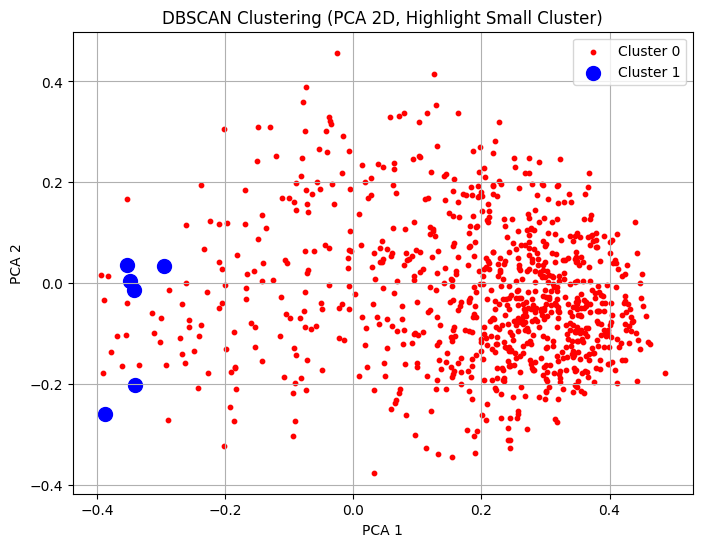

In [370]:
pca = PCA(n_components=2)
reduced_2d = pca.fit_transform(embeddings)
filtered_embeddings = embeddings[labels != -1]
filtered_labels = labels[labels != -1]
reduced_2d = reduced_2d[labels != -1]
colors = ['red', 'blue']
sizes = [10, 100]
plt.figure(figsize=(8, 6))
for cluster_id in np.unique(filtered_labels):
    idx = filtered_labels == cluster_id
    plt.scatter(reduced_2d[idx, 0], reduced_2d[idx, 1],
                c=colors[cluster_id], label=f"Cluster {cluster_id}", s=sizes[cluster_id])
plt.title("DBSCAN Clustering (PCA 2D, Highlight Small Cluster)")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.legend()
plt.grid(True)
plt.show()



In [371]:
import numpy as np
print("Unique labels in filtered DBSCAN:", np.unique(filtered_labels))


Unique labels in filtered DBSCAN: [0 1]


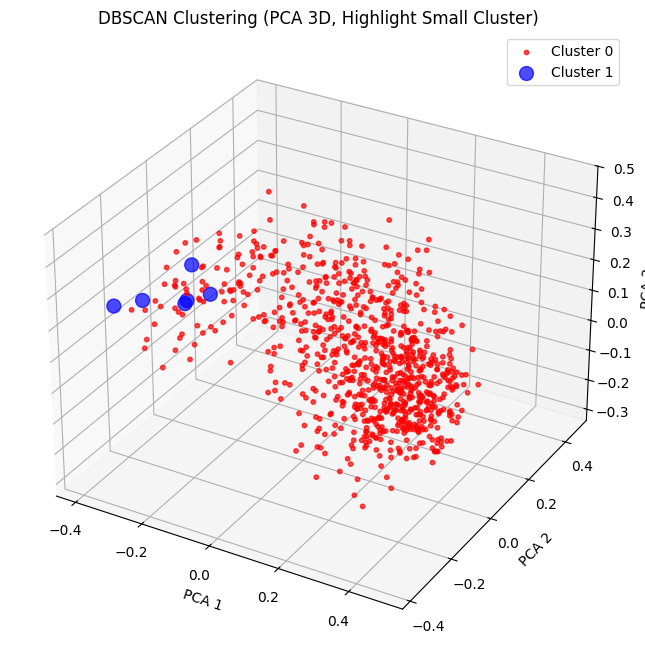

In [372]:
from mpl_toolkits.mplot3d import Axes3D

pca = PCA(n_components=3)
reduced_3d = pca.fit_transform(embeddings)
filtered_embeddings = embeddings[labels != -1]
filtered_labels = labels[labels != -1]
reduced_3d = reduced_3d[labels != -1]

colors = ['red', 'blue']
sizes = [10, 100]

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

for cluster_id in np.unique(filtered_labels):
    idx = filtered_labels == cluster_id
    ax.scatter(reduced_3d[idx, 0], reduced_3d[idx, 1], reduced_3d[idx, 2],
               c=colors[cluster_id], s=sizes[cluster_id], alpha=0.7, label=f"Cluster {cluster_id}")

ax.set_title("DBSCAN Clustering (PCA 3D, Highlight Small Cluster)")
ax.set_xlabel("PCA 1")
ax.set_ylabel("PCA 2")
ax.set_zlabel("PCA 3")
ax.legend()
plt.show()


In [373]:
clusters = set(filtered_labels)

for cluster_id in clusters:
    print(f"\nCluster {cluster_id} examples:\n")
    samples = df[df['dbscan_cluster'] == cluster_id]['music'].sample(2, random_state=cluster_id)
    for i, lyric in enumerate(samples):
        print(f"  Examlpe{i+1}:\n{lyric[:300]}...\n")


Cluster 0 examples:

  Examlpe1:
first vers streetbal yall would call biggi small awe flow wouldnt wanna cough ball hall yeah biggi small proper titl size littl skill larg like tidal wave peopl get stage love spread longitudin effect transvers speaka posit transcend univers shine like sun music starburst swear im apollo ego swallow...

  Examlpe2:
first wann thank connect mean thank everi part step mean thank step left mapquest right never follow rest back light never want stress come hype that one impress trap life sinc tag desk couldnt tell couldnt match wit best back wasnt forward back want call tap want come around lam stori know like sid...


Cluster 1 examples:

  Examlpe1:
enter gate rage moonlight funer truth fate insid circl time tunnel mad spread fear shall aris innoc young face twist sad sorrow wont fall grace insid circl time tunnel mad spread fear shall aris wind blew cold ici sent rose grave insid hand time shall aris forev shall rememb insid soul im truth fait...

  Exa

In [379]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import numpy as np
scaler = StandardScaler()
scaled = scaler.fit_transform(embeddings)
pca = PCA(n_components=3)
reduced = pca.fit_transform(scaled)
n_clusters = 3
agg = AgglomerativeClustering(n_clusters=n_clusters, linkage='ward')
labels = agg.fit_predict(reduced)
sil_score = silhouette_score(reduced, labels)
print(f"Hierarchical Clustering (k=3) -> Silhouette Score: {sil_score:.4f}")
df["hierarchical_cluster"] = labels


Hierarchical Clustering (k=3) -> Silhouette Score: 0.2329


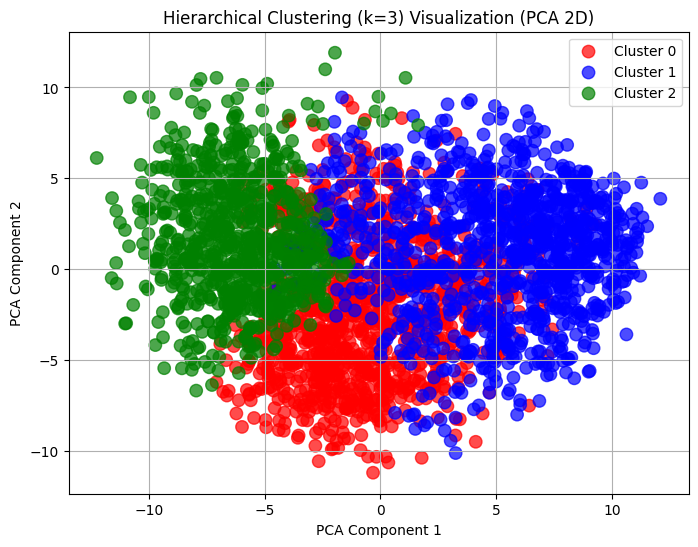

In [380]:

pca_vis = PCA(n_components=3)
reduced_2d = pca_vis.fit_transform(reduced)

colors = ['red', 'blue', 'green']
sizes = [80] * n_clusters

plt.figure(figsize=(8, 6))
for cluster_id in np.unique(labels):
    idx = labels == cluster_id
    plt.scatter(reduced_2d[idx, 0], reduced_2d[idx, 1],c=np.array([colors[cluster_id]] * sum(idx)),label=f"Cluster {cluster_id}", s=sizes[cluster_id], alpha=0.7)
plt.title("Hierarchical Clustering (k=3) Visualization (PCA 2D)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.legend()
plt.grid(True)
plt.show()

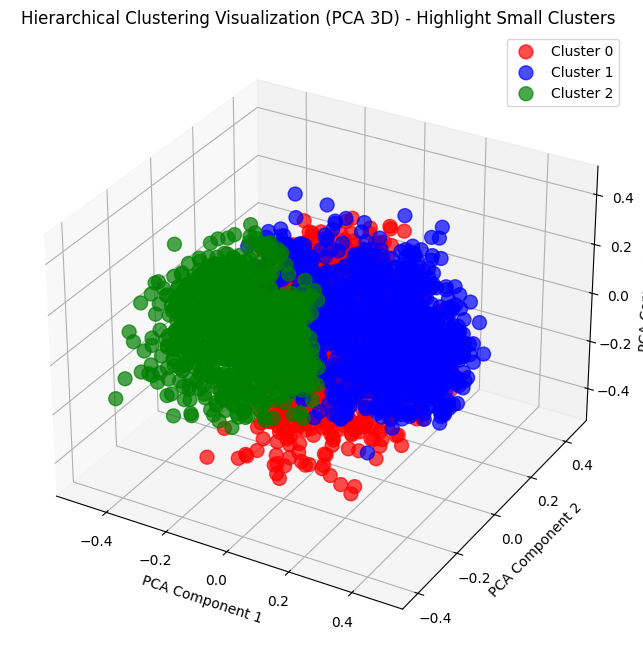

In [376]:
from mpl_toolkits.mplot3d import Axes3D 
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA
pca = PCA(n_components=3)
reduced_embeddings_3d = pca.fit_transform(embeddings)

colors = ['red', 'blue', 'green']
sizes = [100, 100, 100]

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

for cluster_id in np.unique(labels):
    idx = labels == cluster_id
    ax.scatter(reduced_embeddings_3d[idx, 0], reduced_embeddings_3d[idx, 1], reduced_embeddings_3d[idx, 2],
               c=np.array([colors[cluster_id]] * sum(idx)),
               label=f"Cluster {cluster_id}", s=sizes[cluster_id], alpha=0.7)

ax.set_title("Hierarchical Clustering Visualization (PCA 3D) - Highlight Small Clusters")
ax.set_xlabel("PCA Component 1")
ax.set_ylabel("PCA Component 2")
ax.set_zlabel("PCA Component 3")
ax.legend()
plt.show()


In [384]:
for cluster_id in np.unique(labels):
    cluster_data = df[df["hierarchical_cluster"] == cluster_id]["music"]
    samples = cluster_data.sample(2, random_state=cluster_id)
    print(f"\nCluster {cluster_id} - Sample texts:\n")
    for i, text in enumerate(samples):
        print(f" Sample {i+1}:\n{text[:300]}...\n")



Cluster 0 - Sample texts:

 Sample 1:
lay come take sure see see see see want fall asleep hold hand dream good plan second guess weve aliv gone ah ah ah ah ah ah ah ah go nonsens ador cant go gone see see see see want fall asleep hold hand dream good plan second guess weve aliv gone fall asleep hold hand dream big plan second guess weve...

 Sample 2:
ever find ever come perhap imag mind creat dri tear without sleep cant see heart never fail deceiv im ride upon etern watch fade memori ask noth faith hope let tide pull anymor ill easili come back hear call go home see face long ago ill fall ground among leav stare bluest sky peac alon eye close ni...


Cluster 1 - Sample texts:

 Sample 1:
realiti slip mind cave submit web constantli spin edg straightjacket drag world belong hell mind alway see nightmar terror plant etern dead space head escap realiti see imag fake insomnia drive drive head dont lose conscious lie bed look outsid tighten grip death sicken laughter that begin rip eyeli.

## تفاوت یادگیری نظارت‌شده و بدون نظارت

### Supervised: داده‌ها برچسب‌دار هستند (مثلاً متن با ژانر مشخص)، مدل با استفاده از این برچسب‌ها یاد می‌گیرد.



### Unsupervised: داده‌ها برچسب ندارند، مدل خودش ساختار داده‌ها را کشف می‌کند (مثل خوشه‌بندی).

یادگیری نظارت‌شده دقت بالاتر ولی نیاز به داده برچسب‌دار دارد؛ یادگیری بدون نظارت مستقل از برچسب است و برای کشف ساختار پنهان داده‌ها کاربرد دارد.

## دلیل استفاده از بردار ویژگی 

بردار ویژگی متنی، متن را به صورت اعداد تبدیل می‌کند تا ماشین بتواند آن را پردازش کند. این بردارها اطلاعات معنایی را در قالب عددی نگه می‌دارند و باعث می‌شوند مدل‌ها شباهت‌ها و تفاوت‌های معنایی را بهتر درک کنند.

## توضیح الگوریتم‌های خوشه‌بندی 

### K-Means: 

خوشه‌بندی بر اساس فاصله و مرکز خوشه‌ها، نیازمند تعیین تعداد خوشه‌ها است.

### DBSCAN: 

خوشه‌بندی بر اساس چگالی نقاط، نیازی به تعیین تعداد خوشه ندارد و می‌تواند نویزها را تشخیص دهد.

### Hierarchical:

ساخت درخت خوشه ای به صورت تکراری که به دو صورت باتن آپ یا تاپ دون انجام میشه

## روش‌های بردارسازی متن

### TF-IDF: وزن‌دهی به کلمات بر اساس فراوانی و اهمیت.

### Word2Vec/GloVe: مدل‌های کلمه محور که شباهت معنایی کلمات را در فضای برداری حفظ می‌کنند.

### Sentence Transformers (مثل مدل all-MiniLM-L6-v2): تبدیل جملات به بردارهای عددی که معنای جمله را بهتر حفظ می‌کنند.

مزایا: بردارهای معنایی کیفیت بهتری برای تحلیل متن دارند و مدل‌های پیشرفته مثل ترنسفورمر توانایی درک عمیق‌تری دارند.

## درباره مدل all-MiniLM-L6-v2

مدل سبکی است با بردارهای ۳۸۴ بعدی

بهینه شده برای تشخیص شباهت جملات

سریع و با دقت مناسب

## روش elbow در K-Means

روش elbow نمودار تغییرات مقدار inerta (مجموع فاصله نمونه‌ها تا مرکز خوشه) را بر حسب تعداد خوشه‌ها رسم می‌کند. نقطه‌ای که تغییرات کاهش چشمگیر داشته باشد (شبیه آرنج) بهترین تعداد خوشه‌ها را نشان می‌دهد.

## مقایسه نتایج خوشه‌بندی 

K-Means: ساده و سریع، ولی نیازمند تعداد خوشه مشخص است و فرض شکل کروی دارد.

DBSCAN: مناسب داده‌های نویزی و خوشه‌های با شکل نامنظم، ولی حساس به پارامترها.

Hierarchical: ساختار درختی که دید بهتری از خوشه‌ها می‌دهد، ولی محاسباتی‌تر است.

برای داده‌های ترانه که معنایی و پیچیده است، Hierarchical و K-Means با کاهش بعد و بردارسازی مناسب، نتایج خوبی داده‌اند. DBSCAN چون توزیع چگالی متغیری دارد، ممکن است خوشه‌های کوچک زیادی داشته باشد.



## PCA

یک روش ریاضی برای کاهش ابعاد داده‌هاست که با حفظ بیشترین مقدار اطلاعات (واریانس)، داده‌های پیچیده را در ابعاد کمتر نمایش می‌دهد.

ابتدا داده‌ها استاندارد می‌شوند (میانگین صفر و واریانس یک).

سپس ماتریس کوواریانس داده‌ها ساخته می‌شود.

بردارهای ویژه و مقدارهای ویژه محاسبه می‌شوند.

داده‌ها روی چند مؤلفه اصلی که بیشترین واریانس را دارند، پروژه داده می‌شوند.